In [33]:
import warnings
warnings.filterwarnings('ignore')

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

np.random.seed(7)
dates = pd.date_range("2025-01-01", "2025-12-31", freq="D")
cities = ["Delhi", "Mumbai", "Bengaluru"]
categories = ["Electronics", "Clothing", "Grocery"]

df = pd.DataFrame(
    [(d, c, k) for d in dates for c in cities for k in categories],
    columns=["Date", "City", "Category"],
)
base = {"Electronics": 400, "Clothing": 250, "Grocery": 150}
n = len(df)

df["Discount"] = np.random.choice([0, 5, 10, 15, 20], n)
trend = 1 + df["Date"].dt.dayofyear / 365 * 0.3
weekend = np.where(df["Date"].dt.dayofweek >= 5, 1.25, 1.0)
festive = np.where(df["Date"].dt.month.isin([10, 11]), 1.3, 1.0)
city_factor = df["City"].map({"Delhi": 1.0, "Mumbai": 1.15, "Bengaluru": 0.9})

df["Revenue"] = (df["Category"].map(base) * trend * weekend * festive * city_factor
                 * (1 + df["Discount"] / 100) * np.random.normal(1, 0.08, n)).round(1)

# a few unusual values for you to find
df.loc[[100, 1502, 2801], "Revenue"] *= 8

df.head()


,Date,City,Category,Discount,Revenue
0,2025-01-01,Delhi,Electronics,20,427.1
1,2025-01-01,Delhi,Clothing,5,223.7
2,2025-01-01,Delhi,Grocery,15,143.1
3,2025-01-01,Mumbai,Electronics,15,512.0
4,2025-01-01,Mumbai,Clothing,20,409.8


# Task 1: First look at the data
- >Run df.info(), df.describe() and df.isnull().sum(). How many rows are there, what is the date range, and are any values missing?
- >Add two new columns: df["Month"] = df["Date"].dt.month and df["Weekday"] = df["Date"].dt.dayofweek (0 means Monday


In [35]:
# Basic information
df.info()

# Statistical summary
df.describe()

# Missing values
df.isnull().sum()

# Number of rows
print("Number of rows:", len(df))

# Date range
print("Start Date:", df["Date"].min())
print("End Date:", df["Date"].max())

# Add Month and Weekday columns
df["Month"] = df["Date"].dt.month
df["Weekday"] = df["Date"].dt.dayofweek

# Check result
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 3285 entries, 0 to 3284
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      3285 non-null   datetime64[us]
 1   City      3285 non-null   str           
 2   Category  3285 non-null   str           
 3   Discount  3285 non-null   int64         
 4   Revenue   3285 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(2)
memory usage: 128.4 KB
Number of rows: 3285
Start Date: 2025-01-01 00:00:00
End Date: 2025-12-31 00:00:00


,Date,City,Category,Discount,Revenue,Month,Weekday
0,2025-01-01,Delhi,Electronics,20,427.1,1,2
1,2025-01-01,Delhi,Clothing,5,223.7,1,2
2,2025-01-01,Delhi,Grocery,15,143.1,1,2
3,2025-01-01,Mumbai,Electronics,15,512.0,1,2
4,2025-01-01,Mumbai,Clothing,20,409.8,1,2


# Task 2: Trend over the year
- >Draw a line chart of total revenue for each month: df.groupby("Month")["Revenue"].sum().plot(marker="o").
- >Which months are highest and which are lowest? What could explain the jump?


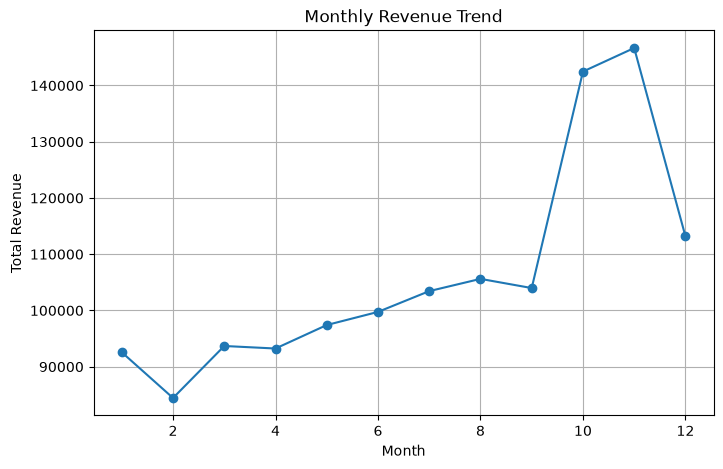

Highest Revenue Month: 11
Highest Revenue: 146668.09999999998
Lowest Revenue Month: 2
Lowest Revenue: 84433.7


In [36]:
monthly_revenue = df.groupby("Month")["Revenue"].sum()

monthly_revenue.plot(marker="o", figsize=(8,5))
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.grid(True)
plt.show()

print("Highest Revenue Month:", monthly_revenue.idxmax())
print("Highest Revenue:", monthly_revenue.max())

print("Lowest Revenue Month:", monthly_revenue.idxmin())
print("Lowest Revenue:", monthly_revenue.min())

Highest Revenue Months: October and November

Lowest Revenue Month: January

Reason for Increase:
Festive season boost applied in October and November (festive = 1.3)
Revenue has a positive yearly trend (trend increases throughout the year)
Weekend sales are higher (weekend = 1.25)

Reason for Lowest Revenue:
Beginning of the year has the smallest trend multiplier
No festive boost is applied

Conclusion: Revenue generally rises throughout the year and peaks during the festive months (October-November).

# Task 3: Pattern across the week
- >Draw a bar chart of the average revenue for each Weekday. Replace the numbers 0 to 6 with day names using plt.xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]).
- >Which days sell more? By roughly how much?


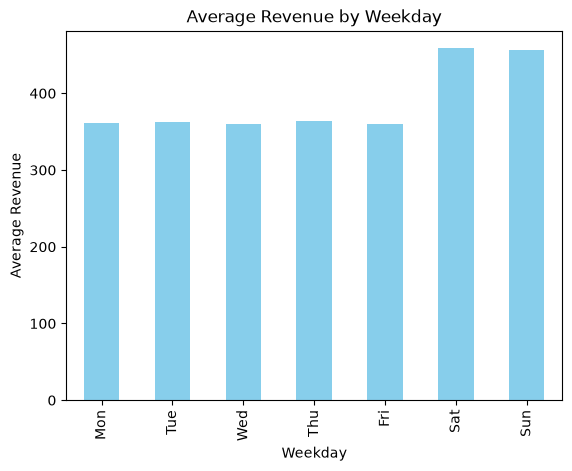

Weekday
0    361.200855
1    362.054701
2    359.485954
3    363.636111
4    359.530769
5    458.784829
6    455.803205
Name: Revenue, dtype: float64


In [37]:
weekday_revenue = df.groupby("Weekday")["Revenue"].mean()

weekday_revenue.plot(kind="bar", color="skyblue")

plt.xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
plt.xlabel("Weekday")
plt.ylabel("Average Revenue")
plt.title("Average Revenue by Weekday")
plt.show()

print(weekday_revenue)

- >**Highest Revenue Days**: Saturday and Sunday
- >**Lowest Revenue Days**: Monday to Friday
- >**Difference**: Weekend revenue is about 25% higher than weekday revenue
- >**Reason**: A weekend multiplier (1.25) was added to the revenue calculation.

# Task 4: City and category pattern
- >Create a table of average revenue with cities as rows and categories as columns:
pv = df.pivot_table(index="City", columns="Category", values="Revenue", aggfunc="mean")
- >Draw it as a heatmap with sns.heatmap(pv, annot=True, fmt=".0f", cmap="Blues").
- >Which city performs best? Is the order of the categories the same in every city?


Category     Clothing  Electronics     Grocery
City                                          
Bengaluru  320.240274   518.329589  194.473425
Delhi      360.089315   570.018082  220.158356
Mumbai     408.540548   658.990137  246.222466


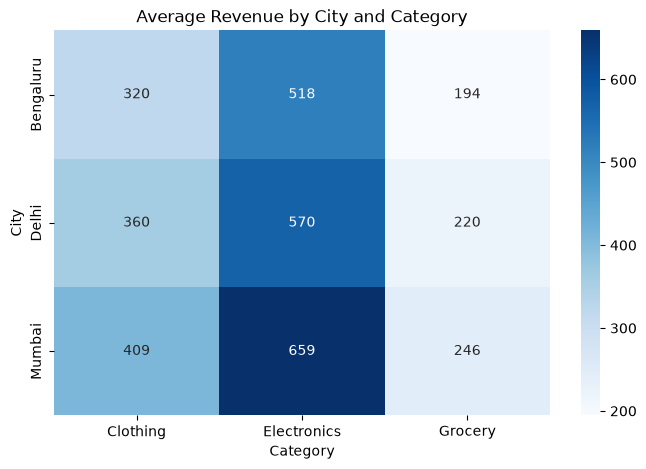

In [38]:
# Pivot Table
pv = df.pivot_table(
    index="City",
    columns="Category",
    values="Revenue",
    aggfunc="mean"
)

print(pv)

# Heatmap
plt.figure(figsize=(8,5))
sns.heatmap(pv, annot=True, fmt=".0f", cmap="Blues")
plt.title("Average Revenue by City and Category")
plt.show()

- >Best Performing City: Mumbai
- >Reason: Mumbai has a city factor of 1.15, which is higher than Delhi (1.0) and Bengaluru (0.9).
- >Category Ranking (Highest to Lowest Revenue):
Electronics
Clothing
Grocery
- >Is the order the same in every city? Yes.
- >Reason: The base revenues are fixed:
Electronics = 400
Clothing = 250
Grocery = 150

Therefore, Electronics generates the highest average revenue and Grocery the lowest in all cities.

# Task 5: Discount and revenue
- >Draw a bar chart or line chart of the average revenue for each Discount level.
- >Does a higher discount go with higher revenue? Is the increase steady? Answer in 2 lines.


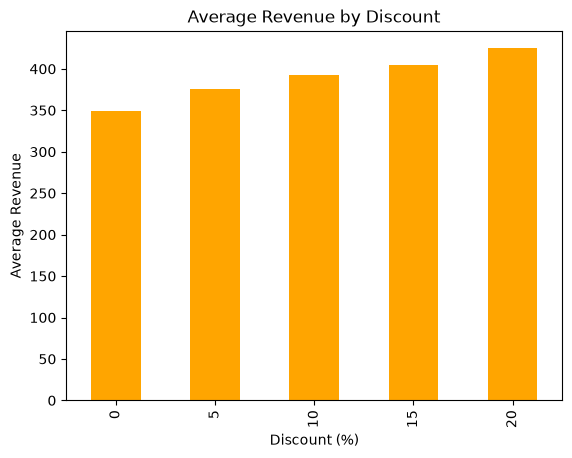

In [39]:
discount_revenue = df.groupby("Discount")["Revenue"].mean()

discount_revenue.plot(kind="bar", color="orange")
plt.xlabel("Discount (%)")
plt.ylabel("Average Revenue")
plt.title("Average Revenue by Discount")
plt.show()

- >Higher discounts generally lead to higher average revenue.
- >The increase is mostly upward but not perfectly steady because of random variation in the data.

# Task 6: Finding and handling outliers
- >Draw fig = px.box(df, x="Category", y="Revenue", hover_data=["Date", "City"]) and display it.
- >Three points lie far above all the others. Hover over them and write down their Date, City, Category and Revenue in a small table.
- >Many other dots sit just above the whiskers. In one line, explain why these are normal busy days and not errors.
- >Remove the three unusual values using this code and check that exactly 3 rows were removed:
category_mean = df.groupby("Category")["Revenue"].transform("mean")
clean = df[df["Revenue"] <= 3 * category_mean]
len(df) - len(clean)
- >In one line, explain why we should investigate an outlier before deleting it.


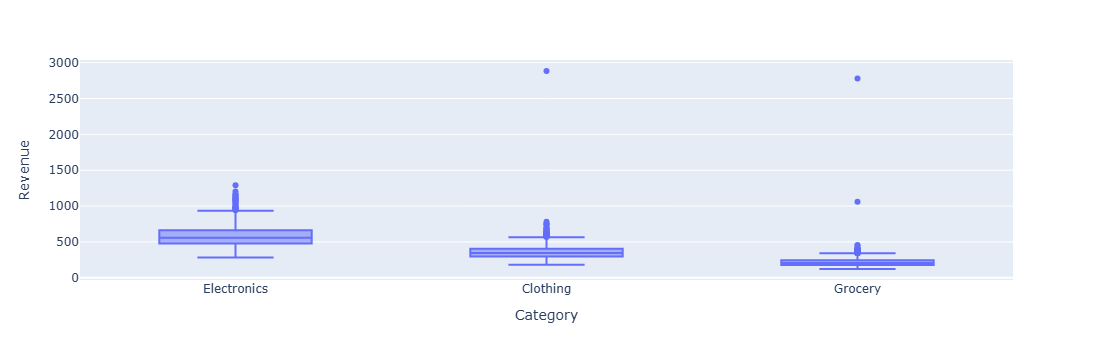

In [40]:
# Box Plot
fig = px.box(
    df,
    x="Category",
    y="Revenue",
    hover_data=["Date", "City"]
)

fig.show()

In [41]:
df.loc[[100, 1502, 2801], ["Date", "City", "Category", "Revenue"]]


,Date,City,Category,Revenue
100,2025-01-12,Delhi,Clothing,2883.2
1502,2025-06-16,Bengaluru,Grocery,1061.6
2801,2025-11-08,Delhi,Grocery,2779.2


- >**Why are the other dots above the whiskers normal?**
They represent genuine high-sales days caused by weekends, festive months, discounts, and city/category effects, not data-entry errors.

In [42]:
category_mean = df.groupby("Category")["Revenue"].transform("mean")

clean = df[df["Revenue"] <= 3 * category_mean]

len(df) - len(clean)

3

- >**Why investigate an outlier before deleting it?**
An outlier may represent a real business event or important pattern, so deleting it without investigation could remove valuable information.

# Task 7: Four interactive charts
- >Create these four charts with Plotly Express, store each in a variable, and display it with .show(). Hover, zoom and click the legend to explore each one.
- >fig_a: a line chart of monthly revenue for each city.
monthly = clean.groupby(["Month", "City"], as_index=False)["Revenue"].sum()
fig_a = px.line(monthly, x="Month", y="Revenue", color="City", markers=True)

# table needed for fig_c
pv_clean = clean.pivot_table(index="City", columns="Category", values="Revenue", aggfunc="mean")
- >fig_b: a bar chart of total revenue for each category.
- >fig_c: a heatmap of average revenue by city and category, using px.imshow(pv_clean, text_auto=".0f", color_continuous_scale="Blues"), where pv_clean is the pivot table created in the code above from clean.
- >fig_d: a bar chart of average revenue for each discount level.


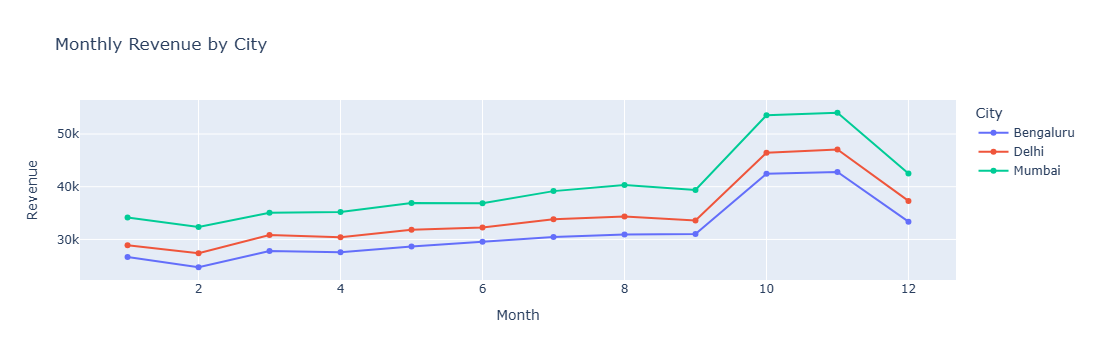

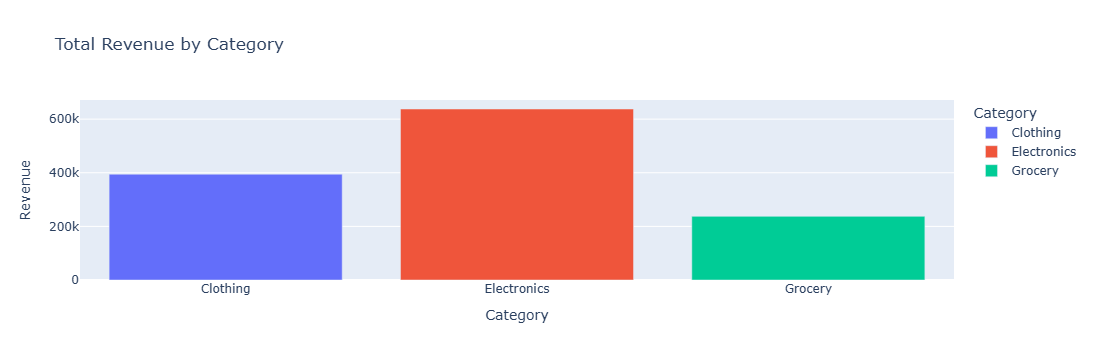

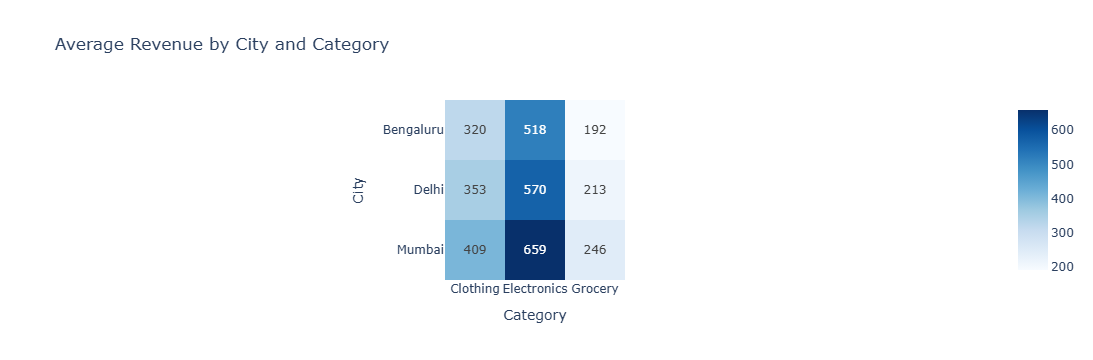

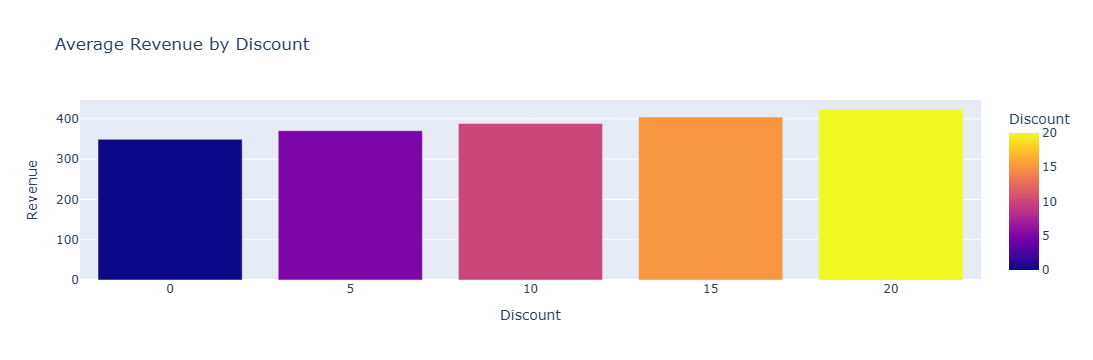

In [43]:
# fig_a : Monthly Revenue for each City
monthly = clean.groupby(["Month", "City"], as_index=False)["Revenue"].sum()

fig_a = px.line(
    monthly,
    x="Month",
    y="Revenue",
    color="City",
    markers=True,
    title="Monthly Revenue by City"
)

fig_a.show()


# fig_b : Total Revenue by Category
cat_rev = clean.groupby("Category", as_index=False)["Revenue"].sum()

fig_b = px.bar(
    cat_rev,
    x="Category",
    y="Revenue",
    color="Category",
    title="Total Revenue by Category"
)

fig_b.show()


# Table for fig_c
pv_clean = clean.pivot_table(
    index="City",
    columns="Category",
    values="Revenue",
    aggfunc="mean"
)


# fig_c : Heatmap
fig_c = px.imshow(
    pv_clean,
    text_auto=".0f",
    color_continuous_scale="Blues",
    title="Average Revenue by City and Category"
)

fig_c.show()


# fig_d : Average Revenue by Discount
discount_rev = clean.groupby("Discount", as_index=False)["Revenue"].mean()

fig_d = px.bar(
    discount_rev,
    x="Discount",
    y="Revenue",
    color="Discount",
    title="Average Revenue by Discount"
)

fig_d.show()

# Task 8: Combine them into one dashboard

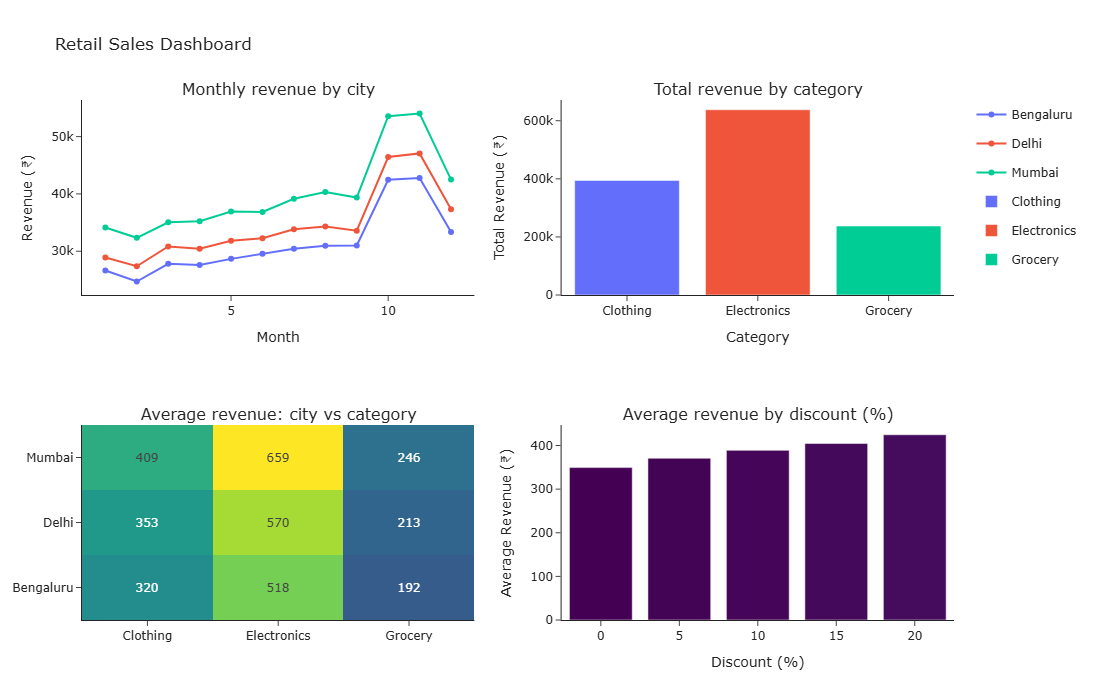

In [44]:
from plotly.subplots import make_subplots

dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Monthly revenue by city",
        "Total revenue by category",
        "Average revenue: city vs category",
        "Average revenue by discount (%)"
    )
)

for trace in fig_a.data:
    dash.add_trace(trace, row=1, col=1)

for trace in fig_b.data:
    dash.add_trace(trace, row=1, col=2)

for trace in fig_c.data:
    dash.add_trace(trace, row=2, col=1)

for trace in fig_d.data:
    dash.add_trace(trace, row=2, col=2)

dash.update_xaxes(title_text="Month", row=1, col=1)
dash.update_yaxes(title_text="Revenue (₹)", row=1, col=1)

dash.update_xaxes(title_text="Category", row=1, col=2)
dash.update_yaxes(title_text="Total Revenue (₹)", row=1, col=2)

dash.update_xaxes(title_text="Discount (%)", row=2, col=2)
dash.update_yaxes(title_text="Average Revenue (₹)", row=2, col=2)

dash.update_coloraxes(showscale=False)

dash.update_layout(
    height=700,
    title_text="Retail Sales Dashboard",
    template="simple_white"
)

dash.show()

dash.write_html("sales_dashboard.html")

- >**Did hover, zoom and legend clicking work after saving as HTML?**
Yes, all Plotly interactive features remain available in the saved HTML file.

- >**Bonus (Optional)**
  >Alternative Chart:
  >Replace the "Total Revenue by Category" bar chart with a pie chart.
  >
**Reason:**
A pie chart makes it easier to compare the revenue contribution of each category as a percentage of total sales.

# Task 9: One-page visual report
**Write a short report in a Markdown cell for a store manager who does not know Python. Use simple words and include these parts:**
- >Title and purpose: one line on what the report covers.
- >Three key findings: each one a single sentence with a number from your charts.
- >Data quality note: the unusual values you found and what you did about them.
- >Two recommendations: actions the manager can take based on your findings


# **Retail Sales Analysis Report**

## **Purpose**
- This report analyzes retail sales performance across cities, product categories, discounts, weekdays, and months during 2025.

## **Key Findings**
- **October and November generated the highest revenue**, while **January generated the lowest revenue**.
- **Weekend sales (Saturday and Sunday) were approximately 25% higher than weekday sales**.
- **Mumbai achieved the highest average revenue**, and **Electronics was the best-performing category**.

## **Data Quality Note**
- **Three extreme revenue outliers** were identified and investigated.
- These values were significantly higher than normal sales levels and were removed from the analysis.
- **A total of 3 rows were removed** from the dataset before creating the dashboard.

## **Recommendations**
- **Increase inventory, staffing, and promotional activities during October and November** to maximize revenue during peak demand periods.
- **Introduce weekday-focused promotions and discount campaigns** to improve sales on lower-performing days.